In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

# ============================================================
# SETTINGS
# ============================================================

N = 2_000

HALF_SPREAD = 0.03      # quote +/- 3 cents around reservation price
INVENTORY_SKEW = 0.015  # move quote centre 1.5c per inventory unit
MAX_INVENTORY = 5

BASE_FILL_PROB = 0.08
TOXICITY = 3.0

FEE = 0.002


# ============================================================
# LATENT FAIR VALUE
# ============================================================

fair_value = np.empty(N)

fair_value[0] = 100

fair_value[1:] = (
    100
    + np.cumsum(
        rng.normal(
            0,
            0.025,
            N - 1
        )
    )
)


# ============================================================
# MARKET MAKER
# ============================================================

inventory = 0
cash = 0

rows = []


for t in range(N - 1):

    fv = fair_value[t]
    future_fv = fair_value[t + 1]

    # --------------------------------------------------------
    # INVENTORY-AWARE FAIR / RESERVATION PRICE
    #
    # long inventory  -> shift quotes DOWN
    # short inventory -> shift quotes UP
    # --------------------------------------------------------

    reservation_price = (
        fv
        - INVENTORY_SKEW * inventory
    )


    # --------------------------------------------------------
    # SET BID AND ASK
    # --------------------------------------------------------

    bid = (
        reservation_price
        - HALF_SPREAD
    )

    ask = (
        reservation_price
        + HALF_SPREAD
    )


    # --------------------------------------------------------
    # INVENTORY LIMITS
    #
    # If already very long, stop bidding.
    # If already very short, stop offering.
    # --------------------------------------------------------

    quote_bid = (
        inventory < MAX_INVENTORY
    )

    quote_ask = (
        inventory > -MAX_INVENTORY
    )


    # --------------------------------------------------------
    # TOY FILL PROCESS
    #
    # If price is about to fall:
    # sellers are more likely to hit our BID.
    #
    # If price is about to rise:
    # buyers are more likely to hit our ASK.
    #
    # This creates adverse selection.
    # --------------------------------------------------------

    future_move = (
        future_fv
        - fv
    )

    p_bid_fill = (
        BASE_FILL_PROB
        * np.exp(
            -TOXICITY
            * future_move
        )
    )

    p_ask_fill = (
        BASE_FILL_PROB
        * np.exp(
            +TOXICITY
            * future_move
        )
    )

    p_bid_fill = np.clip(
        p_bid_fill,
        0,
        0.5
    )

    p_ask_fill = np.clip(
        p_ask_fill,
        0,
        0.5
    )


    bid_fill = (
        quote_bid
        and
        rng.random() < p_bid_fill
    )

    ask_fill = (
        quote_ask
        and
        rng.random() < p_ask_fill
    )


    # Only allow one fill per step
    # for simplicity

    if bid_fill and ask_fill:

        if rng.random() < 0.5:
            ask_fill = False

        else:
            bid_fill = False


    event = "NONE"
    fill_price = np.nan


    # --------------------------------------------------------
    # BID FILLED
    #
    # Someone sells to us.
    # We BUY.
    # Inventory increases.
    # --------------------------------------------------------

    if bid_fill:

        inventory += 1

        cash -= (
            bid
            + FEE
        )

        event = "BUY @ BID"

        fill_price = bid


    # --------------------------------------------------------
    # ASK FILLED
    #
    # Someone buys from us.
    # We SELL.
    # Inventory decreases.
    # --------------------------------------------------------

    elif ask_fill:

        inventory -= 1

        cash += (
            ask
            - FEE
        )

        event = "SELL @ ASK"

        fill_price = ask


    # --------------------------------------------------------
    # MARK INVENTORY TO FAIR VALUE
    # --------------------------------------------------------

    wealth = (
        cash
        + inventory * future_fv
    )


    rows.append({

        "t":
            t,

        "fair_value":
            fv,

        "reservation_price":
            reservation_price,

        "bid":
            bid,

        "ask":
            ask,

        "event":
            event,

        "fill_price":
            fill_price,

        "inventory":
            inventory,

        "future_fv":
            future_fv,

        "cash":
            cash,

        "wealth":
            wealth,

    })


df = pd.DataFrame(rows)

df.head(20)

,t,fair_value,reservation_price,bid,ask,event,fill_price,inventory,future_fv,cash,wealth
0,0,100.000000,100.000000,99.970000,100.030000,NONE,NaN,0,100.000031,0.000000,0.000000
1,1,100.000031,100.000031,99.970031,100.030031,SELL @ ASK,100.030031,-1,100.007499,100.028031,0.020531
2,2,100.007499,100.022499,99.992499,100.052499,NONE,NaN,-1,100.000646,100.028031,0.027385
3,3,100.000646,100.015646,99.985646,100.045646,NONE,NaN,-1,99.978381,100.028031,0.049650
4,4,99.978381,99.993381,99.963381,100.023381,NONE,NaN,-1,99.967014,100.028031,0.061016
5,5,99.967014,99.982014,99.952014,100.012014,NONE,NaN,-1,99.942223,100.028031,0.085808
6,6,99.942223,99.957223,99.927223,99.987223,BUY @ BID,99.927223,0,99.943727,0.098808,0.098808
7,7,99.943727,99.943727,99.913727,99.973727,SELL @ ASK,99.973727,-1,99.977232,100.070534,0.093302
8,8,99.977232,99.992232,99.962232,100.022232,BUY @ BID,99.962232,0,99.964927,0.106302,0.106302
9,9,99.964927,99.964927,99.934927,99.994927,NONE,NaN,0,99.949415,0.106302,0.106302


In [2]:
fills = df[
    df["event"] != "NONE"
].copy()

fills[
    [
        "t",
        "fair_value",
        "bid",
        "ask",
        "event",
        "fill_price",
        "inventory",
        "future_fv",
        "wealth",
    ]
].head(30)

,t,fair_value,bid,ask,event,fill_price,inventory,future_fv,wealth
1,1,100.000031,99.970031,100.030031,SELL @ ASK,100.030031,-1,100.007499,0.020531
6,6,99.942223,99.927223,99.987223,BUY @ BID,99.927223,0,99.943727,0.098808
7,7,99.943727,99.913727,99.973727,SELL @ ASK,99.973727,-1,99.977232,0.093302
8,8,99.977232,99.962232,100.022232,BUY @ BID,99.962232,0,99.964927,0.106302
23,23,99.758187,99.728187,99.788187,SELL @ ASK,99.788187,-1,99.764968,0.127521
29,29,99.686615,99.671615,99.731615,SELL @ ASK,99.731615,-2,99.689448,0.243208
31,31,99.651194,99.651194,99.711194,BUY @ BID,99.651194,-1,99.639251,0.329659
36,36,99.600901,99.585901,99.645901,SELL @ ASK,99.645901,-2,99.600088,0.412635
43,43,99.578545,99.578545,99.638545,SELL @ ASK,99.638545,-3,99.580448,0.508011
84,84,99.634688,99.649688,99.709688,SELL @ ASK,99.709688,-4,99.629756,0.438020


In [4]:
first_buy = fills[
    fills["event"] == "BUY @ BID"
].index[0]

df.loc[
    first_buy:first_buy + 10,
    [
        "t",
        "fair_value",
        "reservation_price",
        "bid",
        "ask",
        "event",
        "inventory",
    ]
]

,t,fair_value,reservation_price,bid,ask,event,inventory
6,6,99.942223,99.957223,99.927223,99.987223,BUY @ BID,0
7,7,99.943727,99.943727,99.913727,99.973727,SELL @ ASK,-1
8,8,99.977232,99.992232,99.962232,100.022232,BUY @ BID,0
9,9,99.964927,99.964927,99.934927,99.994927,NONE,0
10,10,99.949415,99.949415,99.919415,99.979415,NONE,0
11,11,99.961661,99.961661,99.931661,99.991661,NONE,0
12,12,99.970583,99.970583,99.940583,100.000583,NONE,0
13,13,99.973219,99.973219,99.943219,100.003219,NONE,0
14,14,99.949957,99.949957,99.919957,99.979957,NONE,0
15,15,99.949226,99.949226,99.919226,99.979226,NONE,0


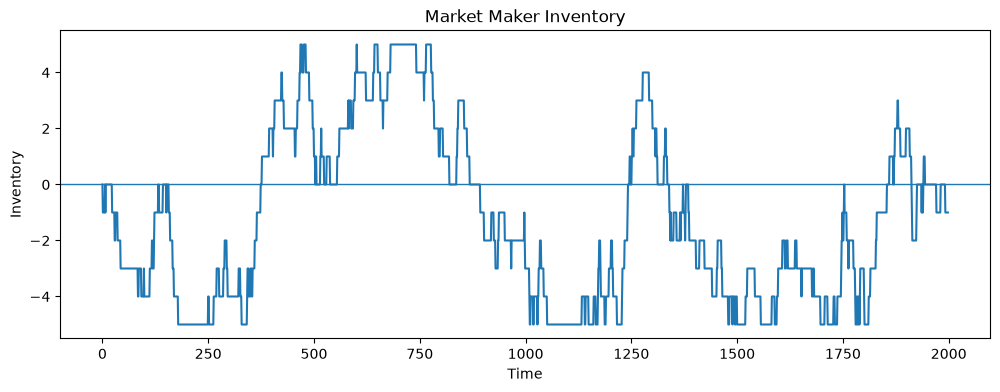

In [5]:
plt.figure(figsize=(12, 4))

plt.plot(
    df["t"],
    df["inventory"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Inventory")

plt.title(
    "Market Maker Inventory"
)

plt.show()

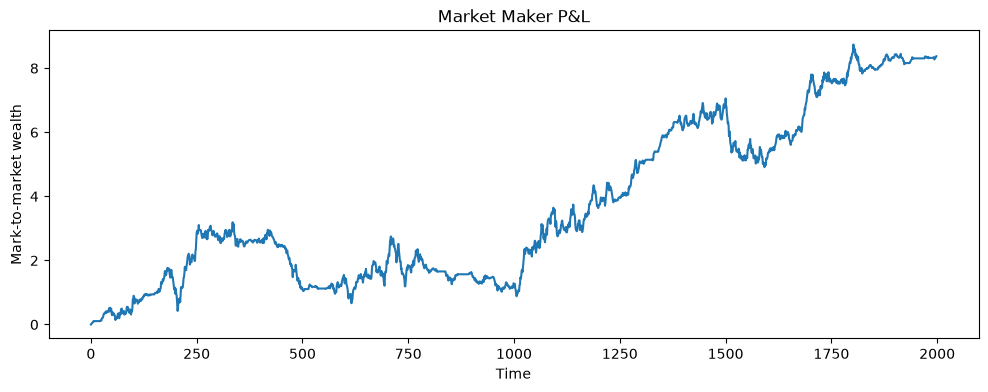

In [6]:
plt.figure(figsize=(12, 4))

plt.plot(
    df["t"],
    df["wealth"]
)

plt.xlabel("Time")

plt.ylabel(
    "Mark-to-market wealth"
)

plt.title(
    "Market Maker P&L"
)

plt.show()

In [7]:
fills = df[
    df["event"] != "NONE"
].copy()


fills["markout"] = np.where(

    fills["event"] == "BUY @ BID",

    # Buy:
    # want future FV ABOVE our purchase price
    fills["future_fv"]
    - fills["fill_price"],

    # Sell:
    # want future FV BELOW our sale price
    fills["fill_price"]
    - fills["future_fv"]

)


fills[
    [
        "event",
        "fill_price",
        "fair_value",
        "future_fv",
        "markout",
    ]
].head(20)

,event,fill_price,fair_value,future_fv,markout
1,SELL @ ASK,100.030031,100.000031,100.007499,0.022531
6,BUY @ BID,99.927223,99.942223,99.943727,0.016504
7,SELL @ ASK,99.973727,99.943727,99.977232,-0.003505
8,BUY @ BID,99.962232,99.977232,99.964927,0.002695
23,SELL @ ASK,99.788187,99.758187,99.764968,0.023218
29,SELL @ ASK,99.731615,99.686615,99.689448,0.042167
31,BUY @ BID,99.651194,99.651194,99.639251,-0.011944
36,SELL @ ASK,99.645901,99.600901,99.600088,0.045813
43,SELL @ ASK,99.638545,99.578545,99.580448,0.058096
84,SELL @ ASK,99.709688,99.634688,99.629756,0.079932


In [8]:
print(
    "Average markout:",
    fills["markout"].mean()
)

print(
    "Negative markout rate:",
    (
        fills["markout"] < 0
    ).mean()
)

print(
    "Number of fills:",
    len(fills)
)

Average markout: 0.020501739945609544
Negative markout rate: 0.3824561403508772
Number of fills: 285


## Market Making: The Core Mental Model

A market maker is **not** guaranteed to buy at the bid and then sell at the ask.

Instead:

$$
\boxed{
\text{Accept temporary inventory}
\rightarrow
\text{manage it}
\rightarrow
\text{try to earn the spread}
}
$$

The basic economics are:

$$
\boxed{
\text{Spread capture}
>
\text{adverse selection}
+
\text{inventory losses}
+
\text{fees}
+
\text{hedging costs}
}
$$

---

## What Happens After One Side Fills?

Suppose:

$$
F_t = 100.00
$$

and the market maker quotes:

$$
99.97 / 100.03
$$

If the bid is hit, the market maker buys at:

$$
99.97
$$

and becomes long.

It is now exposed to market risk until it either:

- gets filled on the ask,
- reprices the ask,
- hedges elsewhere,
- or crosses the spread to reduce inventory.

So your intuition is correct: **market making does involve market risk between fills**.

---

## Inventory Skew

The market maker does not usually leave the same quotes unchanged after a fill.

A simple inventory-adjusted reservation price is:

$$
r_t = F_t - \lambda q_t
$$

where:

- $F_t$ = fair value
- $q_t$ = inventory
- $\lambda$ = inventory-risk parameter

If:

$$
F_t = 100
$$

$$
q_t = +1
$$

$$
\lambda = 0.015
$$

then:

$$
r_t = 99.985
$$

Instead of quoting:

$$
99.97 / 100.03
$$

the market maker might now quote:

$$
99.955 / 100.015
$$

This does two things:

- lowers the bid, reducing the chance of buying more;
- lowers the ask, increasing the chance of selling the existing long inventory.

---

## Spread Capture Is the Reward for Risk

Good case:

$$
\text{Buy}=99.97
$$

$$
\text{Sell}=100.03
$$

so:

$$
\text{Gross capture}=0.06
$$

But suppose fair value falls after the buy and the market maker is forced to sell at:

$$
99.79
$$

Then:

$$
99.79 - 99.97 = -0.18
$$

So one bad inventory event can wipe out several successful spread captures.

---

## Adverse Selection

Fills are not random.

For a passive buy, define the markout as:

$$
M_h = F_{t+h} - P_{\text{fill}}
$$

If:

$$
P_{\text{fill}} = 99.97
$$

and shortly afterwards:

$$
F_{t+h} = 99.90
$$

then:

$$
M_h = -0.07
$$

That means the market moved against you after the fill.

This is why a market maker cares about both:

$$
P(\text{fill})
$$

and:

$$
E[M_h \mid \text{fill}]
$$

More fills are not necessarily better if those fills have worse markouts.

---

## Where Fair Value Fits

Fair value determines where the market maker wants to centre its quotes.

If the public mid is:

$$
100.00
$$

but your model estimates:

$$
F_t = 100.05
$$

then quoting around $100.00$ may leave your ask too cheap.

A better fair value helps you avoid stale or toxic quotes.

So for market making, a better FV often means:

$$
\boxed{
\text{fewer adverse fills}
}
$$

rather than simply more fills.

---

## If Inventory Gets Too Large

As inventory risk increases, the market maker can become progressively more aggressive:

$$
\text{skew quotes}
\rightarrow
\text{reduce size}
\rightarrow
\text{stop quoting one side}
\rightarrow
\text{hedge elsewhere}
\rightarrow
\text{cross the spread}
$$

For example, if you become long BTC on Hyperliquid, you might immediately sell BTC on Binance to neutralise the exposure.

---

## Final Mental Model

Market making is approximately:

$$
\boxed{
\text{earn many small spread captures}
}
$$

while trying to prevent:

$$
\boxed{
\text{inventory risk + adverse selection}
}
$$

from overwhelming those gains.

The goal is not to eliminate market risk. It is to make that risk **small, short-lived, measurable, and actively controlled**.